# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Fateh Noor <br>**
**Student ID: 023-24-0110 <br>**
**Section: D <br>**
**GitHub: https://github.com/noormangi17/ML-Tasks/tree/main/Lab7<br>**
**Kaggle: https://www.kaggle.com/noormangi<br>**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration
## Problem Definition — Dataset A: SMS Spam Classification

The objective of this task is to classify SMS messages as either spam or ham (legitimate messages). The dataset contains text messages labeled as `spam` or `ham`. This is a binary classification problem because the target variable has only two classes. The model learns patterns from message text to identify unwanted messages and help users avoid spam.

## Problem Definition — Dataset B: Airline Sentiment Classification

The objective of this task is to classify airline-related tweets as positive or negative based on their text. The dataset contains tweets labeled with their sentiment, and neutral tweets are removed to make the task binary classification. The model learns language patterns that indicate positive or negative opinions about airlines. This can help airlines understand customer feedback and improve their services.

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [177]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df = pd.read_csv("spam.csv", encoding="latin-1")
print(f"Dataset shape: {df.shape}")
print(f"Dataset Head: {df.head()}")
print(f"Class balance: {df["v1"].value_counts()}")
print(f"Class balance percentage: {df["v1"].value_counts(normalize=True)*100}")

Dataset shape: (5572, 5)
Dataset Head:      v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
Class balance: v1
ham     4825
spam     747
Name: count, dtype: int64
Class balance percentage: v1
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [178]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets=pd.read_csv("Tweets.csv")
tweets.drop(tweets[tweets["airline_sentiment"]=="neutral"].index,inplace=True)
print(f"Dataset shape\n: {tweets.shape}")
print(f"Dataset Head: {tweets.head()}")
print(f"Class balance: {tweets["airline_sentiment"].value_counts()}")
print(f"Class balance: {tweets["airline_sentiment"].value_counts(normalize=True)}")

Dataset shape
: (11541, 15)
Dataset Head:              tweet_id airline_sentiment  airline_sentiment_confidence  \
1  570301130888122368          positive                        0.3486   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   
5  570300767074181121          negative                        1.0000   
6  570300616901320704          positive                        0.6745   

  negativereason  negativereason_confidence         airline  \
1            NaN                     0.0000  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   
5     Can't Tell                     0.6842  Virgin America   
6            NaN                     0.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
1                    NaN    jnardino                 NaN         

**Answer 2 (Task A — spam):**
The goal is to identify whether an SMS message is legitimate or spam based on its text. This is a binary classification problem because there are only two target classes: ham and spam. The model learns patterns from labeled messages and predicts the class of new messages.

**Answer 2 (Task B — sentiment):**
The goal is to determine whether a tweet expresses a positive or negative opinion about an airline. This is a binary classification problem because neutral tweets are excluded, leaving only two target classes: positive and negative. The model learns sentiment-related patterns from tweet text to classify new tweets.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [179]:
# Task 3 — clean text
df["v2"]=df["v2"].str.lower()                                  
df["v2"]=df["v2"].str.replace(r"[^a-z0-9\s]", " ", regex=True)  
df["v2"]=df["v2"].str.replace(r"\s+", " ", regex=True).str.strip() 


In [180]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
df["v1"]=df["v1"].map({
    "ham":0,
    "spam":1
})
y_spam=df["v1"]
x_spam=df["v2"]
x_train_spam,x_test_spam,y_train_spam,y_test_spam=train_test_split(
    x_spam,y_spam,test_size=0.2,random_state=42,stratify=y_spam
)
vectorizer_spam=TfidfVectorizer()
x_train_spam_vec=vectorizer_spam.fit_transform(x_train_spam)
x_test_spam_vec=vectorizer_spam.transform(x_test_spam)
vocab_size_spam=vectorizer_spam.get_feature_names_out()
print(f"Vocabulary size: {len(vocab_size_spam)}")


Vocabulary size: 7658


**Answer 4 (why fit on training data only):**
The vectorizer must be fit only on the training data to prevent data leakage, which occurs when information from the test data influences the training process. This ensures a fair evaluation of the model on unseen data and gives a more realistic estimate of its performance.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy of MultinomialNB on spam dataset: 0.9605
Precision of MultinomialNB on spam dataset: 1.0
Recall of MultinomialNB on spam dataset: 0.7047
F1 Score of MultinomialNB on spam dataset: 0.8268


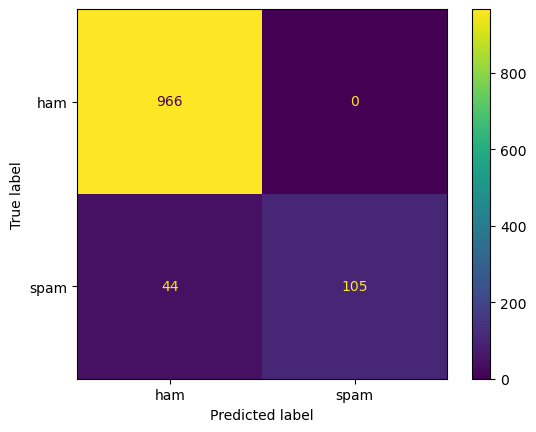

In [181]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb=MultinomialNB()
nb.fit(x_train_spam_vec,y_train_spam)
nb_pred=nb.predict(x_test_spam_vec)
acc_nb=round(accuracy_score(y_test_spam,nb_pred),4)
prec_nb=round(precision_score(y_test_spam,nb_pred),4)
rec_nb=round(recall_score(y_test_spam,nb_pred),4)
f1_nb=round(f1_score(y_test_spam,nb_pred),4)
print(f"Accuracy of MultinomialNB on spam dataset: {acc_nb}")
print(f"Precision of MultinomialNB on spam dataset: {prec_nb}")
print(f"Recall of MultinomialNB on spam dataset: {rec_nb}")
print(f"F1 Score of MultinomialNB on spam dataset: {f1_nb}")
cm=confusion_matrix(y_test_spam,nb_pred)
ConfusionMatrixDisplay(cm,display_labels=["ham","spam"]).plot()


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9605|
| Precision |1.0 |
| Recall |0.7047 |
| F1-score |0.8268 |

**Answer 6:**
A false positive is worse in this application because a legitimate message may be incorrectly marked as spam and the user could miss an important message. Therefore, I would prioritize precision, which measures how many messages predicted as spam are actually spam. High precision reduces false positives and helps ensure that genuine messages remain in the inbox. However, recall is also important because low recall allows more spam messages to reach the inbox.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [182]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
log_prob=nb.feature_log_prob_
top_spam_index=np.argsort(log_prob[1])[-15:][::-1]
top_ham_index=np.argsort(log_prob[0])[-15:][::-1]
top_spam_words=vocab_size_spam[top_spam_index]
top_ham_words=vocab_size_spam[top_ham_index]
print(f"Top spam worda:\n {top_spam_words}")
print(f"Top ham worda:\n {top_ham_words}")


Top spam worda:
 ['to' 'call' 'free' 'your' 'you' 'txt' 'now' 'for' 'or' 'claim' 'from'
 'the' 'mobile' 'stop' 'ur']
Top ham worda:
 ['you' 'to' 'the' 'in' 'me' 'my' 'and' 'it' 'is' 'ok' 'that' 'can' 'are'
 'so' 'not']


**Answer 7:**
These results generally match my intuition because spam messages often use promotional language, while ham messages tend to contain ordinary conversational words. However, common words alone do not always determine whether a message is spam or legitimate.

In [190]:
# Task 8 — test your own messages
my_messages = [
     "Congratulations! You have won a free iPhone. Claim your prize now!",
    "Hey, are we meeting at the library tomorrow?",
    "URGENT! You have won a cash prize. Click now to claim!"
]
my_messages_vec=vectorizer_spam.transform(my_messages)
my_messages_pred=nb.predict(my_messages_vec)
for messages,label in zip(my_messages,my_messages_pred):
    label="spam" if label == 1 else "ham"
    print(f"Message: {messages}")
    print(f"Label: {label}\n")

Message: Congratulations! You have won a free iPhone. Claim your prize now!
Label: spam

Message: Hey, are we meeting at the library tomorrow?
Label: ham

Message: URGENT! You have won a cash prize. Click now to claim!
Label: spam



**Answer 8:**
The 15 words most strongly associated with spam include words such as call, free, txt, claim, and mobile. These words often appear in promotional messages and prize offers. The top ham words include you, the, in, me, and my, which are common in everyday personal conversations.



---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [184]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
tweets["text"]=tweets["text"].str.lower()
tweets["text"]=tweets["text"].str.replace(r"[^a-z0-9\s]", " ", regex=True)  
tweets["text"]=tweets["text"].str.replace(r"\s+", " ", regex=True).str.strip() 
tweets["airline_sentiment"]=tweets["airline_sentiment"].map({
    "positive":1,
    "negative":0
})
y_tweet=tweets["airline_sentiment"]
x_tweet=tweets["text"]
x_train_tweet,x_test_tweet,y_train_tweet,y_test_tweet=train_test_split(
    x_tweet,y_tweet,test_size=0.2,random_state=42,stratify=y_tweet
)
vectorizer=TfidfVectorizer()
x_train_tweet_vec=vectorizer.fit_transform(x_train_tweet)
x_test_tweet_vec=vectorizer.transform(x_test_tweet)



**Answer 12:**
_(your answer here)_

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

In [185]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_tweet=MultinomialNB()
nb_tweet.fit(x_train_tweet_vec,y_train_tweet)
nb_tweet_pred=nb_tweet.predict(x_test_tweet_vec)
acc_tweet=round(accuracy_score(y_test_tweet,nb_tweet_pred),4)
prec_tweet=round(precision_score(y_test_tweet,nb_tweet_pred),4)
rec_tweet=round(recall_score(y_test_tweet,nb_tweet_pred),4)
f1_tweet=round(f1_score(y_test_tweet,nb_tweet_pred),4)
print(f"Accuracy of MultimonialNB on tweet dataset: {acc_tweet}")
print(f"Precsion of MultimonialNB on tweet dataset: {prec_tweet}")
print(f"Recall of MultimonialNB on tweet dataset: {rec_tweet}")
print(f"F1 Score of MultimonialNB on tweet dataset: {f1_tweet}")

Accuracy of MultimonialNB on tweet dataset: 0.8268
Precsion of MultimonialNB on tweet dataset: 1.0
Recall of MultimonialNB on tweet dataset: 0.1543
F1 Score of MultimonialNB on tweet dataset: 0.2674


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.8268|
| Precision |1.0 |
| Recall |0.1543 |
| F1-score | 0.2674|

**Answer 14:**
_(your answer here)_

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy |0.9605 | 0.8268|
| Precision |1.0 |1.0 |
| Recall |0.7047 | 0.1543 |
| F1-score | 0.8268| 0.2674|

In [186]:
# Task 18 — train Logistic Regression on Task A's vectorized features
lr=LogisticRegression()
lr.fit(x_train_spam_vec,y_train_spam)
lr_pred=lr.predict(x_test_spam_vec)
acc_lr=round(accuracy_score(y_test_spam,lr_pred),4)
prec_lr=round(precision_score(y_test_spam,lr_pred),4)
rec_lr=round(recall_score(y_test_spam,lr_pred),4)
f1_lr=round(f1_score(y_test_spam,lr_pred),4)
print(f"Accuracy of LogisticRegression on spam dataset: {acc_tweet}")
print(f"Precsion of LogisticRegressi on spam dataset: {prec_tweet}")
print(f"Recall of LogisticRegressi on spam dataset: {rec_tweet}")
print(f"F1 Score of LogisticRegressi on spam dataset: {f1_tweet}")


Accuracy of LogisticRegression on spam dataset: 0.8268
Precsion of LogisticRegressi on spam dataset: 1.0
Recall of LogisticRegressi on spam dataset: 0.1543
F1 Score of LogisticRegressi on spam dataset: 0.2674


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.9605|0.8268 |
| Precision |1.0 |1.0 |
| Recall |0.7047 | 0.1543|
| F1-score |0.8268 |0.2674 |

**Answer 18 (which wins, and does it match expectations):**
Naive Bayes performs better than Logistic Regression for spam classification. It achieves higher accuracy (96.05%), recall (70.47%), and F1-score (82.68%), while both models have 100% precision. This matches my expectations because Naive Bayes often performs well on text classification tasks. Its higher recall means it detects more spam messages while maintaining zero false positives on this test set.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes performed better on the SMS spam classification task than on the airline sentiment task because spam messages often contain distinctive words such as “free,” “call,” “claim,” and “win.” I was surprised that common words such as “you” and “to” appeared among the most predictive words for ham messages. Naive Bayes achieved better accuracy, recall, and F1-score than Logistic Regression on the spam dataset. Both models achieved 100% precision, but Naive Bayes detected more spam messages. One limitation of Naive Bayes is its independence assumption, as words in a message are often related and their meanings can depend on context. For example, the words “free” and “claim” together may indicate spam more strongly than either word alone. Overall, Naive Bayes was effective for text classification, although its performance depends on the dataset and the patterns in the text.

**Answer 20 — Kaggle Notebook Links:**
- Task A: _______
- Task B: _______

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted